# The transversal CCZ of the [[8,3,2]] code

> **In short.**
> * **The setting.** Gates that act on each qubit of a code on its own (*transversal* gates) cannot spread an error from one qubit to another. No code has a transversal gate for every operation, and a gate outside the Clifford group, such as $T$ or CCZ, is the hard part. The [[8,3,2]] code (Campbell 2016; the smallest interesting colour code) puts three logical qubits on the eight corners of a cube, with distance 2. L. Yeh's thesis (Section 6.5, "Diagonal gates", Eqs. (6.44) to (6.46)) shows in ZX that $T$ on four corners and $T^\dagger$ on the other four is a logical CCZ, the gate $|x, y, z\rangle \mapsto (-1)^{xyz} |x, y, z\rangle$.
> * **The program.** The encoder of the thesis's Eq. (6.27) (the inputs x, y, z, a GHZ state on five more qubits, and four CNOTs from each input), then the layer of $T$ and $T^\dagger$ gates.
> * **What the tool finds, from the gates alone.** Question 1: the [[8,3,2]] code after the encoder and after the $T$ layer; its checks are the faces of a cube (drawn). Questions 2 and 3: the encoder is the identity on the logical qubits, and the $T$ layer is a CCZ in every run, transversal. Where the whole circuit goes: it reduces to seven phase gadgets on x, y, z, the CCZ of Eq. (6.44), followed by the encoder. Between the code's ideal encoder and decoder ($E; P; E^\dagger$ of Eq. (6.45)) the tool's reduction passes through the thesis's eight gadgets on x, y, z and the random bit $w$, and ends at the same seven, equal to PyZX's CCZ gate.
> * **How to read the pictures.** Lines are qubits, time runs left to right; green and red dots are Z- and X-spiders. A *phase gadget* is a red dot joined to several green ones with a green leaf carrying a phase $\alpha$: it multiplies by $e^{i\alpha}$ when the parity of those green spiders is 1.
> * The same derivation as the thesis draws it, level by level: [TransversalCCZStepByStep.ipynb](TransversalCCZStepByStep.ipynb). New to codes and ZX-diagrams? Start with [TInjectionWalkthrough.ipynb](TInjectionWalkthrough.ipynb), Part A.

In [1]:
%matplotlib inline
import sys
sys.path.insert(0, '..')
import pyzx as zx
from pyzx.circuit import Circuit
from pyzx.circuit.gates import CCZ, CNOT, T
from pyzx.css import generate_css_encoder_graph
from pyzx.linalg import Mat2
from zxqec.qprogram import QProgram
from zxqec.codes import check_diagram, code_of
from zxqec.gpf import equal_for_all_assignments, phase_polynomial, reduce_gpf, to_gpf_steps
from zxqec.spacetime import draw_program, draw_relaxed_3d

# qubit k here is the thesis's qubit THESIS[k] (Eq. (6.27)); x, y and z enter on qubits 1, 2 and 3
THESIS = [8, 7, 6, 4, 1, 2, 3, 5]
# the wires, as the thesis draws them, top to bottom: its qubits 7, 6, 4, 1, 2, 3, 5, 8
WIRES = {1: 0, 2: 1, 3: 2, 4: 3, 5: 4, 6: 5, 7: 6, 0: 7}
# qubit k sits at the corner CORNERS[k] of the cube (one bit for each of x, y, z)
CORNERS = ['000', '100', '010', '001', '111', '011', '101', '110']
# the encoder of Eq. (6.27): a GHZ state on the thesis's qubits 8, 1, 2, 3, 5, then four CNOTs from each of x, y, z
GHZ = [CNOT(0, 4), CNOT(0, 5), CNOT(0, 6), CNOT(0, 7)]
FROM_X = [CNOT(1, 4), CNOT(1, 6), CNOT(1, 7), CNOT(0, 1)]
FROM_Y = [CNOT(2, 4), CNOT(2, 5), CNOT(2, 7), CNOT(0, 2)]
FROM_Z = [CNOT(3, 4), CNOT(3, 5), CNOT(3, 6), CNOT(0, 3)]
# P of Eq. (6.45): T on the thesis's qubits 1, 4, 6, 7 (an odd number of 1s in their corner), T^dag on 2, 3, 5, 8
P = [T(1), T(2), T(3), T(4), T(5, adjoint=True), T(6, adjoint=True), T(7, adjoint=True), T(0, adjoint=True)]

The qubits are numbered so that the tool's own logical operators of the code (it picks them from the stabilizers alone) are those of x, y and z, in that order; with the thesis's numbering they would be products of them, and the tool would report the encoder as a CNOT circuit and the $T$ layer as a CCZ in that other basis. The pictures draw the wires in the thesis's order.

## 1. The code

Qubit $k$ sits at the corner `CORNERS[k]` of a cube and holds $w \oplus$ (that corner) $\cdot (x, y, z)$, where $w$ is a random bit (the GHZ state): flipping x flips the four corners with a 1 for x. The code's one X check is $X$ on all eight qubits (flipping $w$); its Z checks are $Z$ on the four corners of a face. Drawn by their shape (`check_diagram`, the six faces as Z-checks), they are a cube:

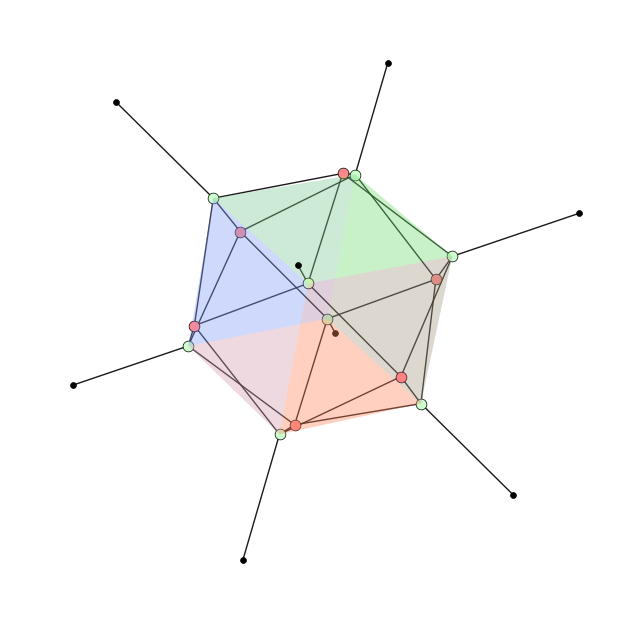

In [2]:
faces = [[int(CORNERS[k][i] == b) for k in range(8)] for i in range(3) for b in '01']
draw_relaxed_3d(check_diagram(faces, kind='Z'), shade='X', boundaries='outward', box=False)

## 2. The program

Five stages: the GHZ state ($|+\rangle$ on qubit 0, $|0\rangle$ on qubits 4 to 7, and four CNOTs), the CNOTs from x, from y and from z, and the $T$ layer. One level up: the encoder and the $T$ layer.

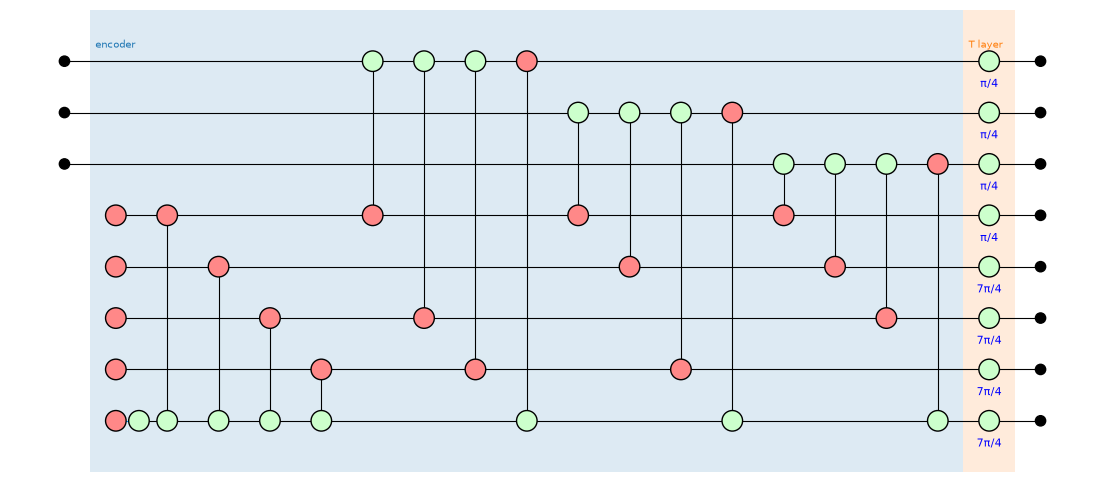

In [3]:
p = QProgram(8, mapping=WIRES, initial_states={0: '+', 4: '0', 5: '0', 6: '0', 7: '0'})
for gates, name in ((GHZ, 'GHZ'), (FROM_X, 'from x'), (FROM_Y, 'from y'), (FROM_Z, 'from z'), (P, 'T layer')):
    c = Circuit(8)
    for gate in gates:
        c.add_gate(gate)
    p.add_circuit(c, name=name)
level = p.group_stages([(0, 3, 'encoder', 'encoder'), (4, 4, 'T layer', 'transversal gate')])
draw_program(p, level=level, show_time=False, labels=False, figsize=(14, 6))

## 3. Question 1: which code

After the encoder: an [[8,3,2]] code. The second line compares it with the code built by PyZX from its X check and the three logical $X$ operators of the cube (`pyzx.css`). After the $T$ layer the code is the same, with non-Clifford logical content: the logical qubits are no longer in a stabilizer state.

In [4]:
print(p.code_at(3))
cube, _ = generate_css_encoder_graph(Mat2([[1] * 8]), Mat2([[int(CORNERS[k][i] == '1') for k in range(8)] for i in range(3)]),
                                     'Z-X')
cube.auto_detect_io()
print("\nthe code of the cube:", p.code_at(3).same_code_as(code_of(cube)))
print("\nafter the T layer:", p.code_at(4).describe().splitlines()[0])

[[8, 3, 2]] CSS code on qubits 0, 1, 2, 3, 4, 5, 6, 7 (at positions 7, 0, 1, 2, 3, 4, 5, 6)
    stabilizer +XXXXXXXX
    stabilizer +ZZZIIIIZ
    stabilizer +ZZIZIIZI
    stabilizer +ZZIIZZII
    stabilizer +ZIZZIZII
    logical X XIXXIXII   logical Z ZZIIIIII
    logical X XXIXIIXI   logical Z ZIZIIIII
    logical X XXXIIIIX   logical Z ZIIZIIII

the code of the cube: True

after the T layer: [[8, 3, 2]] CSS code on qubits 0, 1, 2, 3, 4, 5, 6, 7 (at positions 7, 0, 1, 2, 3, 4, 5, 6) (holding a non-Clifford logical state)


## 4. Questions 2 and 3: what each part does

The level-up table, with the checks of each block's role:

In [5]:
print(p.summary(level))

block      role              code before                        code after  logical action  every run?  checks
0 encoder  encoder           [[1,1,1]] + [[1,1,1]] + [[1,1,1]]  [[8,3,2]]   I               yes         ok
1 T layer  transversal gate  [[8,3,2]]                          [[8,3,2]]   CCZ             yes         ok

Block 0 'encoder' (encoder) -- stages 0, 1, 2, 3
  code before: [[1,1,1]] on qubits 1; [[1,1,1]] on qubits 2; [[1,1,1]] on qubits 3
  code after:  [[8,3,2]] on qubits 0,1,2,3,4,5,6,7
  logical action: deterministic: every run implements I
  ok      encodes 3 logical qubit(s) into [[8,3,2]]
  ok      leaves the logical state unchanged

Block 1 'T layer' (transversal gate) -- stages 4
  code before: [[8,3,2]] on qubits 0,1,2,3,4,5,6,7
  code after:  [[8,3,2]] on qubits 0,1,2,3,4,5,6,7 (non-Clifford logical content)
  logical action: deterministic: every run implements CCZ
  ok      implements CCZ in every run
  ok      transversal: no two qubits of one code block are 

## 5. Where the whole circuit goes

The tool's reduction of the whole circuit (`reduce_gpf`) ends in the diagram below: a Z-spider for each input, x, y and z; one more inside, $w$, the random bit of the GHZ state; an X-spider for each qubit; and seven phase gadgets. Their phases add up to the *phase polynomial*, here $\pi\, x y z$ (in units of $\pi$, with the spiders named by their inputs): the CCZ. So the whole circuit is the CCZ on the inputs, followed by the encoder.

phase polynomial (units of pi): {'x*y*z': '1'}
7 gadgets


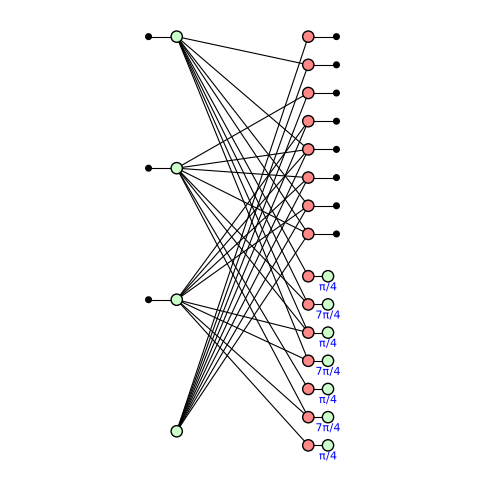

In [6]:
whole = reduce_gpf(p.quantum_graph())
h = whole.graph
names = {next(iter(h.neighbors(b))): v for b, v in zip(h.inputs(), 'xyz')}
poly, gadgets = phase_polynomial(h)
print("phase polynomial (units of pi):", {'*'.join(sorted(names.get(t[1], 'w') for t in m)): str(c) for m, c in poly.items()})
print(len(gadgets), "gadgets")
zx.draw_matplotlib(h, figsize=(6, 6))

Read through the code (question 2 for the $T$ layer, `logical_action`), the tool builds the thesis's $L = E; P; E^\dagger$ of Eq. (6.45): the code's ideal encoder (in parity normal form, each input and $w$ a Z-spider, each qubit an X-spider), the $T$ layer, and the ideal decoder:

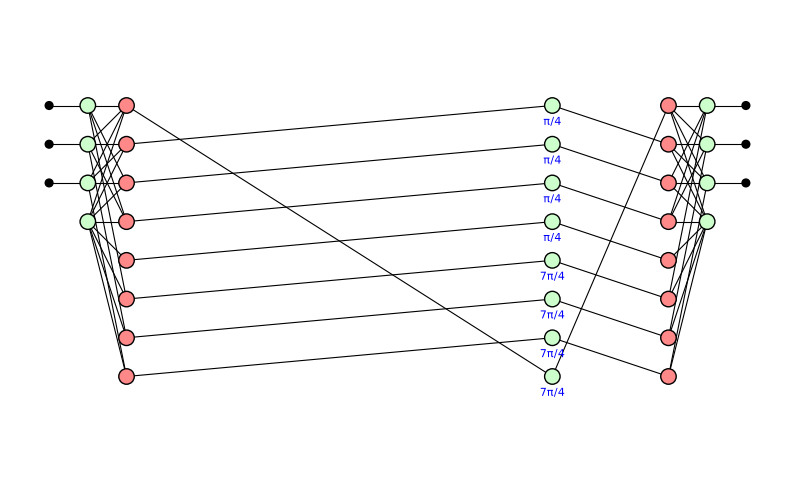

In [7]:
act = p.logical_action(level, 1)
zx.draw_matplotlib(act.composite, figsize=(10, 6))

and reduces it step by step (`to_gpf_steps`; every picture is the same map). The last step has one phase gadget for each $T$ or $T^\dagger$, eight of them, on parities of x, y, z and $w$: the last diagram of Eq. (6.45).

the diagram (32 spiders)
identity spiders removed, neighbours of the same colour fused (28 spiders)
Hadamard edges pushed to the boundary wires, spiders fused (28 spiders)
phases that are not Pauli moved onto gadgets (44 spiders)
the bialgebra rule applied until two layers remain (23 spiders)
one Z-spider per input and one X-spider per output: the normal form (23 spiders)


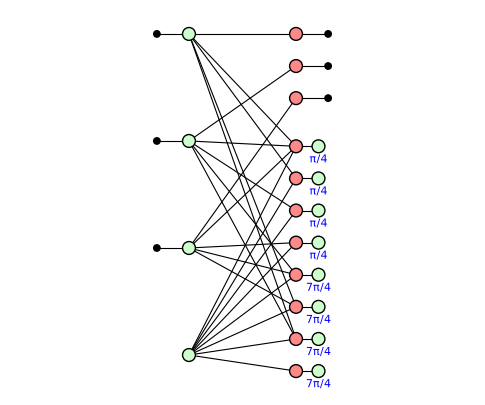

In [8]:
for what, g in to_gpf_steps(act.composite):
    print("{} ({} spiders)".format(what, sum(1 for v in g.vertices() if g.type(v) != zx.VertexType.BOUNDARY)))
zx.draw_matplotlib(g, figsize=(6, 5))

The reduction the tool uses for question 2 (`reduce_gpf`) also simplifies the gadgets as a whole: it writes their phases as one polynomial, in which every term with $w$ cancels, the spider-nest identity of Eq. (6.46). Seven gadgets on x, y and z remain, the right-hand side of Eq. (6.44): $\pi/4$ on each of x, y and z, $-\pi/4$ (shown $7\pi/4$) on each pair, $\pi/4$ on all three. That is the CCZ:

the same map as PyZX's CCZ gate: True


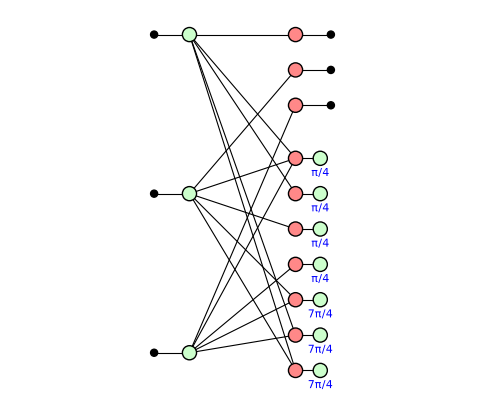

In [9]:
ccz = Circuit(3)
ccz.add_gate(CCZ(0, 1, 2))
print("the same map as PyZX's CCZ gate:", equal_for_all_assignments(act.graph, ccz.to_graph()))
zx.draw_matplotlib(act.graph, figsize=(6, 5))

## 6. Fault tolerance

The $T$ layer is transversal (question 2's check): each qubit gets one gate, so a fault after it is an error on that qubit alone, and the code, of distance 2, notices any error on one qubit. This is the standard argument, not a computation: the tool's circuit distance (`circuit_distance`) does not take $T$ gates, and `z_distance_through_t` removes them, which in a stage of $T$ gates alone leaves no place for a fault. An encoder of an unknown state is never fault tolerant: one fault there can change the logical state.

## Summary

* The tool reads the [[8,3,2]] code off the encoder of Eq. (6.27), and draws its checks as a cube.
* The layer of $T$ and $T^\dagger$ gates is a logical CCZ in every run, and transversal.
* The whole circuit reduces to the CCZ as seven phase gadgets on x, y, z, followed by the encoder; $E; P; E^\dagger$ reduces to the same CCZ, equal to PyZX's CCZ gate.

What is not covered: the circuit distance of the $T$ layer (see above); the steps of Eqs. (6.45) and (6.46) as the thesis draws them are in [TransversalCCZStepByStep.ipynb](TransversalCCZStepByStep.ipynb).